In [ ]:
# @title
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# @title
from google.colab import files

print("Επίλεξε τα αρχεία train.csv και test.csv από τον υπολογιστή σου:")
uploaded = files.upload()

Επίλεξε τα αρχεία train.csv και test.csv από τον υπολογιστή σου:


Saving test.csv to test.csv
Saving train.csv to train (1).csv


In [ ]:
# @title
# Διαβάζουμε τα αρχεία μας
train_full = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(train_full.shape, test.shape)
print(train_full.columns.tolist())
print(train_full.isna().sum())
print(train_full["my_sentiment_type"].value_counts())
print(train_full["Clean_Text"].str.split().str.len().describe())

# 1. ΜΕΤΑΤΡΟΠΗ ΕΤΙΚΕΤΩΝ (ETL): Το Νευρωνικό θέλει αριθμούς, όχι λέξεις!
CLASSES = ["Negative", "Neutral", "Positive"]
label2id = {c: i for i, c in enumerate(CLASSES)}  # Φτιάχνει το λεξικό {'Negative': 0, 'Neutral': 1, 'Positive': 2}

# Αντικαθιστούμε τα κείμενα με τους αριθμούς
y_full = train_full["my_sentiment_type"].map(label2id)
y_test = test["my_sentiment_type"].map(label2id)

# 2. ΧΕΙΡΟΚΙΝΗΤΟ VALIDATION SET
# Κόβουμε το μεγάλο Train σε 80% τελικό Train και 20% Validation, κρατώντας τις αναλογίες (stratify)
train_df, val_df = train_test_split(
    train_full, test_size=0.20, random_state=SEED, stratify=y_full
)

# Αποθηκεύουμε τις τελικές αριθμητικές ετικέτες ως πίνακες Numpy (.values)
y_train = train_df["my_sentiment_type"].map(label2id).values
y_val   = val_df["my_sentiment_type"].map(label2id).values

# 3. ΕΛΕΓΧΟΣ: Τυπώνουμε τα μεγέθη
print(f"Μέγεθος Train: {len(train_df)} κριτικές")
print(f"Μέγεθος Validation: {len(val_df)} κριτικές")
print(f"Μέγεθος Test (Άθικτο): {len(test)} κριτικές\n")

# Τυπώνουμε τις αναλογίες για να αποδείξουμε ότι το stratify δούλεψε τέλεια!
print("Ποσοστά συναισθημάτων στο Train Set (0=Neg, 1=Neu, 2=Pos):")
print(pd.Series(y_train).value_counts(normalize=True).sort_index().round(3))

print("\nΠοσοστά συναισθημάτων στο Validation Set (0=Neg, 1=Neu, 2=Pos):")
print(pd.Series(y_val).value_counts(normalize=True).sort_index().round(3))

(21078, 5) (5270, 5)
['row_id', 'App', 'Clean_Text', 'my_sentiment_type', 'Sentiment']
row_id               0
App                  0
Clean_Text           0
my_sentiment_type    0
Sentiment            0
dtype: int64
my_sentiment_type
Positive    14272
Negative     4377
Neutral      2429
Name: count, dtype: int64
count    21078.000000
mean        18.808521
std         16.357196
min          1.000000
25%          7.000000
50%         15.000000
75%         26.000000
max        383.000000
Name: Clean_Text, dtype: float64
Μέγεθος Train: 16862 κριτικές
Μέγεθος Validation: 4216 κριτικές
Μέγεθος Test (Άθικτο): 5270 κριτικές

Ποσοστά συναισθημάτων στο Train Set (0=Neg, 1=Neu, 2=Pos):
0    0.208
1    0.115
2    0.677
Name: proportion, dtype: float64

Ποσοστά συναισθημάτων στο Validation Set (0=Neg, 1=Neu, 2=Pos):
0    0.208
1    0.115
2    0.677
Name: proportion, dtype: float64


In [ ]:
# @title
from collections import Counter

# Μετράμε όλες τις λέξεις στο Train Set
counter = Counter(w for t in train_df["Clean_Text"] for w in t.split())
total_tokens = sum(counter.values())

print("Διαφορετικές λέξεις στο train:", len(counter))

# Πόσες λέξεις εμφανίζονται μόνο 1 φορά, πόσες >=2 κ.λπ.
for k in [1, 2, 3, 5]:
    n = sum(1 for c in counter.values() if c >= k)
    print(f"Λέξεις που εμφανίζονται >= {k} φορές: {n}")
print()

# Βρίσκουμε την "κάλυψη" (Coverage) του λεξιλογίου
sorted_counts = sorted(counter.values(), reverse=True)
for N in [2000, 5000, 8000, 10000, 15000]:
    covered = sum(sorted_counts[:N]) / total_tokens
    print(f"Οι {N} συχνότερες λέξεις καλύπτουν το {covered:.1%} των συνολικών λέξεων")
print()
print("20 συχνότερες λέξεις:", counter.most_common(20))

Διαφορετικές λέξεις στο train: 15852
Λέξεις που εμφανίζονται >= 1 φορές: 15852
Λέξεις που εμφανίζονται >= 2 φορές: 8608
Λέξεις που εμφανίζονται >= 3 φορές: 6616
Λέξεις που εμφανίζονται >= 5 φορές: 4831

Οι 2000 συχνότερες λέξεις καλύπτουν το 86.3% των συνολικών λέξεων
Οι 5000 συχνότερες λέξεις καλύπτουν το 94.8% των συνολικών λέξεων
Οι 8000 συχνότερες λέξεις καλύπτουν το 97.3% των συνολικών λέξεων
Οι 10000 συχνότερες λέξεις καλύπτουν το 98.2% των συνολικών λέξεων
Οι 15000 συχνότερες λέξεις καλύπτουν το 99.7% των συνολικών λέξεων

20 συχνότερες λέξεις: [('i', 17836), ('it', 5308), ('game', 4045), ('the', 2748), ('s', 2717), ('like', 2543), ('app', 2448), ('this', 2390), ('good', 2236), ('great', 2233), ('get', 2181), ('love', 2055), ('time', 2045), ('t', 1920), ('would', 1530), ('can', 1520), ('really', 1429), ('even', 1364), ('m', 1203), ('update', 1193)]


In [ ]:
# @title
import random

# Μαζεύουμε σε μια λίστα όλες τις λέξεις που εμφανίστηκαν ΑΚΡΙΒΩΣ 1 φορά
words_with_one_freq = [word for word, count in counter.items() if count == 1]

print(f"Συνολικές λέξεις με 1 εμφάνιση: {len(words_with_one_freq)}\n")

# Παίρνουμε ένα τυχαίο δείγμα 30 λέξεων για να δούμε με τα μάτια μας τι είναι
random_sample = random.sample(words_with_one_freq, 30)
print("Τυχαίο δείγμα 30 λέξεων:")
print(random_sample)

Συνολικές λέξεις με 1 εμφάνιση: 7244

Τυχαίο δείγμα 30 λέξεων:
['becz', 'timestamps', 'reshuffling', 'kleptomania', 'reconnects', 'unsolved', 'ethukupa', 'blb', 'moneybait', 'randomizes', 'knack', 'eish', 'yaaaaa', 'behoove', 'plateau', 'arrangement', 'illiterate', 'deseve', 'unrestricted', 'aite', 'advisor', 'susceptible', 'coutse', 'underworked', 'firends', 'fist', 'bollocks', 'chalk', 'ingeniously', 'tn']


In [ ]:
# @title
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Απομονώνουμε καθαρά το κείμενο
X_train_text = train_df['Clean_Text'].astype(str)
X_val_text = val_df['Clean_Text'].astype(str)
X_test_text = test['Clean_Text'].astype(str)

# ΡΥΘΜΙΣΕΙΣ (Υπερπαράμετροι - αποδεδειγμένες πλέον!)
VOCAB_SIZE = 10000  # Κρατάμε το Top 10.000 (Καλύπτει το 98.2%)
MAX_LEN = 100       # Κρατάμε μήκος 100 λέξεις
OOV_TOK = "<OOV>"   # Κωδικός για άγνωστες/σπάνιες λέξεις

# 1. Φτιάχνουμε το Λεξικό ΜΟΝΟ από το Train Set (αποφυγή διαρροής)
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOK)
tokenizer.fit_on_texts(X_train_text)

# 2. Μετατρέπουμε τα κείμενα σε αριθμούς με βάση το λεξικό
train_seq = tokenizer.texts_to_sequences(X_train_text)
val_seq = tokenizer.texts_to_sequences(X_val_text)
test_seq = tokenizer.texts_to_sequences(X_test_text)

# 3. Βάζουμε Padding (0) στο τέλος, ή κόβουμε ('post') όσες ξεπερνάνε τις 100 λέξεις
X_train_pad = pad_sequences(train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val_pad = pad_sequences(val_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

print("Το Στάδιο 2 ολοκληρώθηκε επιτυχώς!")
print(f"Σχήμα X_train_pad: {X_train_pad.shape}")
print(f"Σχήμα X_val_pad: {X_val_pad.shape}")
print(f"Σχήμα X_test_pad: {X_test_pad.shape}")

Το Στάδιο 2 ολοκληρώθηκε επιτυχώς!
Σχήμα X_train_pad: (16862, 100)
Σχήμα X_val_pad: (4216, 100)
Σχήμα X_test_pad: (5270, 100)


In [ ]:
# @title
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Bidirectional, Dense, Dropout

# Υπερπαράμετροι Αρχιτεκτονικής
EMBEDDING_DIM = 64  # Η "εξυπνάδα" του λεξικού
LSTM_UNITS = 64     # Πόσους "νευρώνες" θα έχει ο μηχανισμός μνήμης

model = Sequential()

# shape=(MAX_LEN,) σημαίνει ότι περιμένουμε μια γραμμή με 100 αριθμούς
model.add(Input(shape=(MAX_LEN,)))

# ΣΤΑΔΙΟ 3: Το Layer του Embedding
model.add(Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM, mask_zero=True))

# ΣΤΑΔΙΟ 4: Το BiLSTM Layer
model.add(Bidirectional(LSTM(LSTM_UNITS)))

# Τεχνική "Dropout" (Αντι-Overfitting)
model.add(Dropout(0.5))

# Η "Έξοδος" (Output Layer)
model.add(Dense(3, activation='softmax'))

# COMPILATION: Δίνουμε τις τελικές οδηγίες στο εργοστάσιο
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Τυπώνουμε την αρχιτεκτονική
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,435 (2.69 MB)

 Trainable params: 706,435 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# @title
from tensorflow.keras.callbacks import EarlyStopping

# Ρυθμίζουμε τον "Επόπτη"
early_stop = EarlyStopping(
    monitor='val_loss',         # Παρακολουθεί το λάθος στο Validation Set
    patience=10,                # Δίνουμε patience=10 ώστε να μην διακόψει ποτέ την εκπαίδευση, αλλά στο τέλος να μας επιστρέψει τα καλύτερα βάρη (restore_best_weights=True) - Ιδανικά: 2 συνεχόμενες εποχές, σταματάει
    restore_best_weights=True   # Κρατάει τα βάρη από την καλύτερη εποχή
)

EPOCHS = 10
BATCH_SIZE = 32

print("Ξεκινάει η εκπαίδευση του BiLSTM...\n")

# Το .fit() ξεκινάει τη διαδικασία μάθησης και αποθηκεύει το ιστορικό στη μεταβλητή history
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val), # Ο αμερόληπτος "διαιτητής" μας
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop]
)

print("\nΗ εκπαίδευση ολοκληρώθηκε επιτυχώς!")

Ξεκινάει η εκπαίδευση του BiLSTM...

Epoch 1/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.7732 - loss: 0.5701 - val_accuracy: 0.8297 - val_loss: 0.4397
Epoch 2/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8874 - loss: 0.3142 - val_accuracy: 0.8574 - val_loss: 0.4272
Epoch 3/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9318 - loss: 0.2038 - val_accuracy: 0.8494 - val_loss: 0.5091
Epoch 4/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9518 - loss: 0.1481 - val_accuracy: 0.8456 - val_loss: 0.5524
Epoch 5/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9697 - loss: 0.0959 - val_accuracy: 0.8401 - val_loss: 0.6721
Epoch 6/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.9760 - loss: 0.0750 - val_accuracy: 0.8404 - val_loss: 0.7555
Epoch 7/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9826 - loss: 0.0557 - val_accuracy: 0.8477 - val_loss: 0.7572
Epoch 8/10
527/527 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - acc

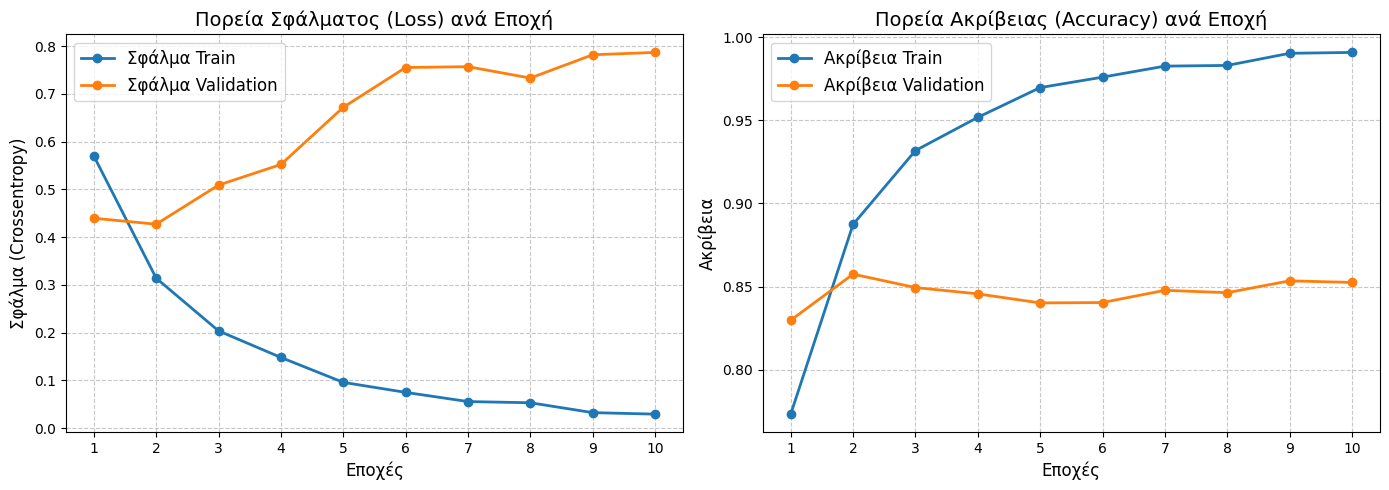

In [ ]:
# @title
import matplotlib.pyplot as plt

# Φτιάχνουμε μια λίστα αριθμών από το 1 έως το 10 (ή όσο είναι οι εποχές μας)
epochs_range = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(14, 5))

# 1ο Γράφημα: Το Σφάλμα (Loss)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['loss'], label='Σφάλμα Train', linewidth=2, marker='o')
plt.plot(epochs_range, history.history['val_loss'], label='Σφάλμα Validation', linewidth=2, marker='o')
plt.title('Πορεία Σφάλματος (Loss) ανά Εποχή', fontsize=14)
plt.xlabel('Εποχές', fontsize=12)
plt.ylabel('Σφάλμα (Crossentropy)', fontsize=12)
plt.xticks(epochs_range)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

# 2ο Γράφημα: Η Ακρίβεια (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['accuracy'], label='Ακρίβεια Train', linewidth=2, marker='o')
plt.plot(epochs_range, history.history['val_accuracy'], label='Ακρίβεια Validation', linewidth=2, marker='o')
plt.title('Πορεία Ακρίβειας (Accuracy) ανά Εποχή', fontsize=14)
plt.xlabel('Εποχές', fontsize=12)
plt.ylabel('Ακρίβεια', fontsize=12)
plt.xticks(epochs_range)
plt.legend(fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

1. Αξιολόγηση στο Test Set (5.270 κριτικές):
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8450 - loss: 0.4308
Τελική Ακρίβεια (Test Accuracy): 0.8450
Τελικό Σφάλμα (Test Loss): 0.4308

2. Το μοντέλο διαβάζει και κάνει προβλέψεις...
165/165 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step

--- 3. Classification Report (Αναλυτική Αναφορά) ---
              precision    recall  f1-score   support

    Negative       0.70      0.82      0.76      1094
     Neutral       0.69      0.47      0.56       608
    Positive       0.91      0.92      0.91      3568

    accuracy                           0.84      5270
   macro avg       0.77      0.74      0.74      5270
weighted avg       0.84      0.84      0.84      5270



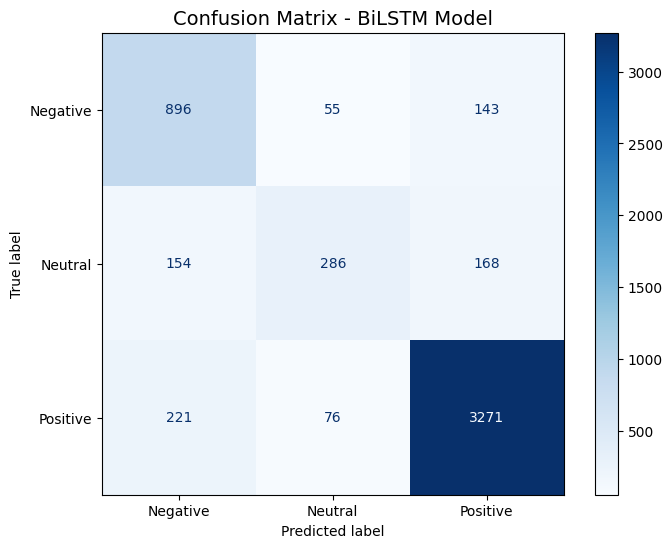

In [ ]:
# @title
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("1. Αξιολόγηση στο Test Set (5.270 κριτικές):")
# Μετατρέπουμε το Pandas Series σε καθαρό NumPy array για να μην μπερδεύεται το Keras
y_test_numpy = np.array(y_test, dtype='int32')

# Το evaluate μας δίνει κατευθείαν το τελικό loss και accuracy
test_loss, test_acc = model.evaluate(X_test_pad, y_test_numpy)
print(f"Τελική Ακρίβεια (Test Accuracy): {test_acc:.4f}")
print(f"Τελικό Σφάλμα (Test Loss): {test_loss:.4f}\n")

print("2. Το μοντέλο διαβάζει και κάνει προβλέψεις...")
# Το predict βγάζει 3 ποσοστά για κάθε κριτική (π.χ. 10% Neg, 20% Neu, 70% Pos)
y_pred_probs = model.predict(X_test_pad)

# Η argmax βρίσκει ποια από τις 3 κατηγορίες είχε το μεγαλύτερο ποσοστό
y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- 3. Classification Report (Αναλυτική Αναφορά) ---")
print(classification_report(y_test_numpy, y_pred, target_names=["Negative", "Neutral", "Positive"]))

# 4. Ζωγραφίζουμε τον Πίνακα Σύγχυσης (Confusion Matrix)
cm = confusion_matrix(y_test_numpy, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Neutral", "Positive"])

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', values_format='d', ax=ax)
plt.title('Confusion Matrix - BiLSTM Model', fontsize=14)
plt.show()

In [ ]:
# @title
# Αποθήκευση ολόκληρου του μοντέλου (Αρχιτεκτονική + Εκπαιδευμένα Βάρη)
model.save('bilstm_sentiment_model.keras')
print("Το μοντέλο αποθηκεύτηκε επιτυχώς!")

Το μοντέλο αποθηκεύτηκε επιτυχώς!


In [ ]:
# @title
import json
from google.colab import files
from sklearn.metrics import confusion_matrix

# 1. Ανέβασε το αρχείο bilstm_sentiment_model.keras από τον φάκελο models
up = files.upload()
model_file = list(up.keys())[0]

# 2. Φόρτωση του μοντέλου
loaded = tf.keras.models.load_model(model_file)
loaded.summary()

# 3. ΕΛΕΓΧΟΣ: είναι το πρώτο μοντέλο;
probs = loaded.predict(X_test_pad)
y_pred = np.argmax(probs, axis=1)
acc = (y_pred == y_test_numpy).mean()
print(f"\nTest accuracy: {acc:.4f}   (αναμενόμενο: 0.8510)")
print(confusion_matrix(y_test_numpy, y_pred))
# αναμενόμενο: [[837 70 187] [139 315 154] [152 83 3333]]

# 4. Αποθήκευση λεξικού
config = {
    "word_index": tokenizer.word_index,
    "vocab_size": VOCAB_SIZE,
    "max_len": MAX_LEN,
    "oov_index": tokenizer.word_index[OOV_TOK],
    "classes": CLASSES,
}
with open("bilstm_tokenizer.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False)

# 5. Αποθήκευση προβλέψεων
pred_df = pd.DataFrame({
    "row_id": test["row_id"],
    "y_true": y_test_numpy,
    "y_pred": y_pred,
    "p_negative": probs[:, 0],
    "p_neutral": probs[:, 1],
    "p_positive": probs[:, 2],
})
pred_df.to_csv("bilstm_test_predictions.csv", index=False)

# 6. Κατέβασμα
files.download("bilstm_tokenizer.json")
files.download("bilstm_test_predictions.csv")

Saving bilstm_sentiment_model.keras to bilstm_sentiment_model (1).keras


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,119,307 (8.08 MB)

 Trainable params: 706,435 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# @title
